# Внимание и маски

В лекции мы разобрали, как запрос сравнивается с ключами и превращает их значения в новый вектор. Теперь соберём это вычисление на NumPy. Начнём с маленьких матриц, а затем изменим доступные связи и посмотрим на результат.

Главный вопрос работы: если позиция не видит будущий токен, может ли изменение этого токена повлиять на её выход?

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## От оценок к весам

Для каждого запроса attention получает строку оценок. После softmax она превращается в веса, сумма которых равна единице. Разберём одну короткую строку, прежде чем обрабатывать целую матрицу.

In [2]:
demo_scores = np.array([0., np.log(2.)])
demo_exp = np.exp(demo_scores)
print("После экспоненты:", demo_exp)
print("После нормировки:", demo_exp / demo_exp.sum())

После экспоненты: [1. 2.]
После нормировки: [0.33333333 0.66666667]


Получились веса примерно 1/3 и 2/3. Каждую экспоненту разделили на сумму экспонент этой строки. Если запросов несколько, у каждого должен быть собственный знаменатель.

## 1. Softmax для нескольких запросов

Напишите `softmax_rows(scores)` для двумерной матрицы. Каждая строка относится к отдельному запросу; нормировать нужно вдоль ключей.

Чтобы большие оценки не приводили к переполнению экспоненты, сначала вычтите максимум каждой строки. Сравните результат для исходной матрицы и для той же матрицы, к которой прибавили 10000. Что произошло с весами?

Позже закрытые ключи будут обозначаться `-np.inf`; их можно принимать. Для `NaN`, `+inf` и строки из одних `-inf` вызывайте `ValueError`: в этих случаях нужного распределения не получится.

In [3]:
def softmax_rows(scores):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 2 or min(scores.shape) == 0:
        raise ValueError("Нужна непустая двумерная матрица")
    if np.isnan(scores).any() or np.isposinf(scores).any() or np.isneginf(scores).all(axis=1).any():
        raise ValueError("Недопустимые оценки или полностью закрытая строка")
    shifted = scores - scores.max(axis=1, keepdims=True)
    exponents = np.exp(shifted)
    return exponents / exponents.sum(axis=1, keepdims=True)

print(softmax_rows([[1000, 1001, 1002], [-2, 0, 1]]))

[[0.09003057 0.24472847 0.66524096]
 [0.03511903 0.25949646 0.70538451]]


In [4]:
scores = np.array([[1000., 1001., 1002.], [-2., 0., 1.]])
p = softmax_rows(scores)
assert np.isfinite(p).all() and np.allclose(p.sum(axis=1), 1)
assert np.allclose(p, softmax_rows(scores + 10000))
assert not np.isclose(p.sum(), 1)  # здесь две отдельные строки-распределения
try:
    softmax_rows([[-np.inf, -np.inf]])
except ValueError:
    pass
else:
    raise AssertionError("Полностью закрытая строка должна быть отклонена")

Для строки (1000;1001;1002) получаются приблизительно (0,090031;0,244728;0,665241). Общий сдвиг оценок не меняет веса. Если студент делит на сумму всей матрицы, обе строки вместе дают 1; здесь же каждая строка должна отдельно давать 1.

## 2. Собираем attention

Используйте написанный softmax, чтобы закончить `attention(Q, K, V, allow=None)`. В заготовке уже есть проверки форм и значений. Допишите вычисление оценок `Q @ K.T / sqrt(d_k)`, применение маски, весов и выхода.

В `allow` True означает разрешённый ключ. Закрытые оценки заменяются на `-np.inf` до softmax. Если маска не передана, доступны все ключи. Функция возвращает пару `(output, weights)`.

Проверка воспроизведёт пример из лекции: Q=K=I₂, V₁=(10;0), V₂=(0;20). Сопоставьте первый выход с ручным расчётом. Какая величина задаёт знаменатель √dₖ — число позиций или число координат ключа?

In [5]:
def attention(Q, K, V, allow=None):
    Q, K, V = [np.asarray(x, dtype=float) for x in [Q, K, V]]
    if any(x.ndim != 2 or min(x.shape) == 0 for x in [Q, K, V]):
        raise ValueError("Нужны непустые матрицы")
    if Q.shape[1] != K.shape[1] or K.shape[0] != V.shape[0]:
        raise ValueError("Несогласованные размерности")
    if not all(np.isfinite(x).all() for x in [Q, K, V]):
        raise ValueError("Входы должны быть конечными")
    if allow is None:
        allow = np.ones((len(Q), len(K)), dtype=bool)
    allow = np.asarray(allow)
    if allow.dtype != bool or allow.shape != (len(Q), len(K)) or not allow.any(axis=1).all():
        raise ValueError("Некорректная маска")
    scores = Q @ K.T / np.sqrt(Q.shape[1])
    weights = softmax_rows(np.where(allow, scores, -np.inf))
    return weights @ V, weights

Q = K = np.eye(2)
V = np.array([[10., 0.], [0., 20.]])
output, weights = attention(Q, K, V)
print("Веса:", weights)
print("Выход:", output)

Веса: [[0.66976155 0.33023845]
 [0.33023845 0.66976155]]
Выход: [[ 6.69761549  6.60476901]
 [ 3.30238451 13.39523099]]


In [6]:
Q = K = np.eye(2)
V = np.array([[10., 0.], [0., 20.]])
output, weights = attention(Q, K, V)
assert np.allclose(weights[0], [0.66976155, 0.33023845])
assert np.allclose(output[0], [6.69761549, 6.60476901])
# Несимметричный cross-пример: два запроса, три ключа, два признака значений.
o, a = attention([[1, 0], [1, 1]], [[1, 0], [0, 1], [2, -1]], [[1, 2], [3, 4], [5, 6]])
assert o.shape == (2, 2) and a.shape == (2, 3)
assert np.allclose(a.sum(axis=1), 1)

Первая строка весов равна примерно (0,66976155;0,33023845), выход — (6,69761549;6,60476901). В cross-примере два запроса и три ключа; он помогает заметить ошибку, которая могла остаться скрытой на квадратной симметричной матрице.

## 3. Закрываем будущее

В заготовке даны причинные маски для двух и трёх позиций. Диагональ разрешена. Примените двухпозиционную маску к Q, K и V, сохранив `masked_output` и `masked_weights`. Сравните первую и вторую строки с предыдущим результатом.

Затем проведите опыт с трёхпозиционной матрицей X. Создайте `V_changed = X.copy()` и прибавьте (100;−50) к строке с индексом 2. В этом опыте Q=K=X; сначала V=X, затем V=V_changed. Меняется только V. Сравните первые два выхода до и после изменения, сначала с `mask3`, затем без маски.

Прежде чем выполнять сравнение, предскажите, в каком из двух вариантов появится разница. Найдите на карте весов связь, которая объясняет результат.

Causal-веса: [[1.         0.        ]
 [0.33023845 0.66976155]]
Causal-выход: [[10.          0.        ]
 [ 3.30238451 13.39523099]]
Максимальное изменение ранних causal-выходов: 0.0
Максимальное изменение без маски: 40.111209267978595


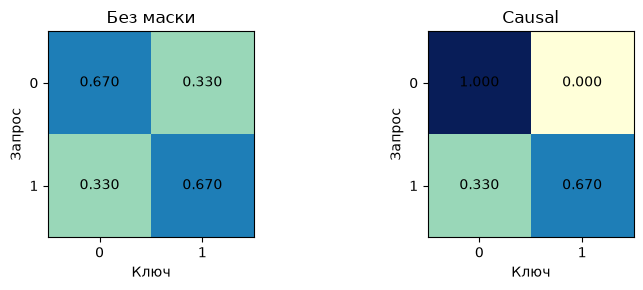

In [7]:
causal = np.tril(np.ones((2, 2), dtype=bool))
masked_output, masked_weights = attention(Q, K, V, causal)
print("Causal-веса:", masked_weights)
print("Causal-выход:", masked_output)

X = np.array([[1., 0.], [0., 1.], [1., 1.]])
V_changed = X.copy(); V_changed[2] += [100., -50.]
mask3 = np.tril(np.ones((3, 3), dtype=bool))
before, _ = attention(X, X, X, mask3)
after, _ = attention(X, X, V_changed, mask3)
open_before, _ = attention(X, X, X)
open_after, _ = attention(X, X, V_changed)
print("Максимальное изменение ранних causal-выходов:", np.max(np.abs(before[:2] - after[:2])))
print("Максимальное изменение без маски:", np.max(np.abs(open_before[:2] - open_after[:2])))
assert np.allclose(before[:2], after[:2])
assert not np.allclose(open_before[:2], open_after[:2])

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, matrix, title in zip(axes, [weights, masked_weights], ["Без маски", "Causal"]):
    ax.imshow(matrix, vmin=0, vmax=1, cmap="YlGnBu")
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center")
    ax.set_title(title); ax.set_xlabel("Ключ"); ax.set_ylabel("Запрос")
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
plt.tight_layout(); plt.show()

In [8]:
assert np.allclose(masked_weights[0], [1, 0])
assert np.allclose(masked_output[0], [10, 0])
assert np.allclose(masked_output[1], output[1])
assert np.all(masked_weights[~causal] == 0)

С причинной маской первый выход двухпозиционного примера становится (10;0), второй остаётся прежним. В трёхпозиционном опыте изменение ранних выходов равно 0 с маской и примерно 40,111209 без неё. Нужно менять только V будущей позиции: если одновременно поменять Q и K, получится другой опыт.

## 4. Не все позиции содержат текст

Считайте последний ключ матрицы X заполнителем padding. Постройте `padding_allow`, закрыв этот ключ для всех запросов, и объедините её с `mask3` через `&`. Сохраните объединённую маску в `combined`, а полученные веса — в `padding_weights`.

Посмотрите на последний столбец. Что с ним произошло? Почему при этом строки весов по-прежнему складываются в единицу?

Проверьте ещё два случая: строку, где закрыты все ключи, и попытку заменить запрещённую оценку нулём. В первом случае нужен `ValueError`. Во втором обратите внимание на вес ключа, который вы собирались исключить.

In [9]:
padding_allow = np.broadcast_to(np.array([True, True, False]), (3, 3)).copy()
combined = padding_allow & mask3
padding_output, padding_weights = attention(X, X, X, combined)
assert np.all(padding_weights[:, 2] == 0)
print("Совмещённые веса:", padding_weights)
print("Неправильная маска нулём:", softmax_rows([[1/np.sqrt(2), 0]]))
try:
    attention(X, X, X, np.zeros((3, 3), dtype=bool))
except ValueError as e:
    print("Ожидаемая ошибка:", e)
else:
    raise AssertionError("Полностью закрытая строка должна быть отклонена")

Совмещённые веса: [[1.         0.         0.        ]
 [0.33023845 0.66976155 0.        ]
 [0.5        0.5        0.        ]]
Неправильная маска нулём: [[0.66976155 0.33023845]]
Ожидаемая ошибка: Некорректная маска


In [10]:
assert padding_weights.shape == (3, 3)
assert np.allclose(padding_weights.sum(axis=1), 1)
assert softmax_rows([[1, 0]])[0, 1] > 0

Последний столбец нулевой, а оставшиеся веса перенормированы. В нижней строке примера получаются (0,5;0,5;0). Маскирование нулём оставляет положительный вес, потому что exp(0)=1. В этом опыте мы исключаем ключ; судьба выхода padding-запроса рассматривается отдельно в полной модели.

## 5. Меняем порядок строк

Для этого опыта уберите все маски. Сравните `attention(X, X, X)` с результатом для переставленных строк `X[permutation]`. Верните выходы к одному порядку и проверьте совпадение.

Теперь прибавьте матрицу Pos. При перестановке содержимого позиционные значения должны остаться на своих местах: сравниваются `X + Pos` и `X[permutation] + Pos`. Сохраните выходы как `with_position` и `permuted_with_position`.

Запишите максимальную разницу `np.max(np.abs(permuted_with_position - with_position[permutation]))` в `position_difference`. Почему результат теперь отличается? Что изменилось бы, если переставить целиком `X + Pos`?

In [11]:
permutation = np.array([2, 0, 1])
Pos = np.array([[0., 0.], [0.5, 0.], [0., 0.5]])
base, _ = attention(X, X, X)
permuted, _ = attention(X[permutation], X[permutation], X[permutation])
print("Ошибка перестановочного равенства без позиций:", np.max(np.abs(permuted - base[permutation])))
assert np.allclose(permuted, base[permutation])
XP = X + Pos
XP_permuted = X[permutation] + Pos
with_position, _ = attention(XP, XP, XP)
permuted_with_position, _ = attention(XP_permuted, XP_permuted, XP_permuted)
position_difference = np.max(np.abs(permuted_with_position - with_position[permutation]))
print("Разница с позиционным сигналом:", position_difference)
assert not np.allclose(permuted_with_position, with_position[permutation])

Ошибка перестановочного равенства без позиций: 0.0
Разница с позиционным сигналом: 0.34908296257561255


In [12]:
assert position_difference > 1e-6

Без масок и позиций расхождение после согласования порядка равно 0. С позиционными добавками, закреплёнными за местами, разница приблизительно 0,349083. Перестановка целого X+Pos вернула бы прежнее свойство, поскольку вместе с содержимым перемещались бы и признаки позиции.

## Разные веса, одинаковые значения

Пусть обе строки V равны (1;2). Предскажите выход для весов (0,9;0,1) и (0,2;0,8), затем проверьте себя. Что можно узнать по карте весов, если не смотреть на сами значения?

In [13]:
same_values = np.array([[1., 2.], [1., 2.]])
first_weights = np.array([0.9, 0.1])
second_weights = np.array([0.2, 0.8])
print(first_weights @ same_values)
print(second_weights @ same_values)

[1. 2.]
[1. 2.]


## Разбор работы

Полученная функция повторяет ручной расчёт: первый выход без маски равен приблизительно (6,6976;6,6048), с причинной маской — (10;0). Изменение значения будущего токена не затронуло ранние выходы, пока связь оставалась закрытой. Без маски влияние появилось.

Padding исключается по другой причине: на этой позиции нет содержимого сообщения. В опыте последний столбец стал нулевым; строка без единого доступного ключа вызвала ошибку. Эти результаты объясняются тем, что маска применяется до softmax.

Перестановка без масок и позиций только переставила выходы. Добавленные позиционные значения изменили входы иначе, поэтому простого совпадения уже не получилось.

Наконец, при V₁=V₂=(1;2) два разных распределения весов дали один результат (1;2). Вопрос на защите: какую часть вычисления показывает карта A и что ещё нужно знать, чтобы объяснить выход? Ожидается связь с V и последующими преобразованиями блока.